# Naive Bayes: prevendo diabetes a partir de glicemia e pressão arterial

Neste desafio construímos um modelo de classificação com o algoritmo **Naive Bayes** para prever se um paciente tem diabetes (`1`) ou não (`0`), usando duas medidas: **glicemia** e **pressão arterial**.

**Como rodar:** execute as células em ordem. No Colab, a primeira célula pede o arquivo `diabetes.csv`.

> Projeto de estudo com dados fornecidos pelo curso. Não serve para diagnóstico de pessoas reais.

## 1. Carregar o dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

sns.set_theme(style="whitegrid")
ARQUIVO = "diabetes.csv"

# No Colab: abre uma caixa para enviar o CSV (se o arquivo ainda não estiver na pasta)
if not os.path.exists(ARQUIVO):
    from google.colab import files
    files.upload()

df = pd.read_csv(ARQUIVO)
print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (995, 3)


,glicemia,pressao_arterial,diabetes
0,40,85,0
1,40,92,0
2,45,63,1
3,45,80,0
4,40,73,1


## 2. Explorar e pré-processar os dados

In [2]:
df.info()
print()
print("Valores nulos por coluna:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 995 entries, 0 to 994
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   glicemia          995 non-null    int64
 1   pressao_arterial  995 non-null    int64
 2   diabetes          995 non-null    int64
dtypes: int64(3)
memory usage: 23.4 KB

Valores nulos por coluna:
glicemia            0
pressao_arterial    0
diabetes            0
dtype: int64


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
glicemia,995.0,44.306533,6.707567,20.0,40.0,45.0,50.0,70.0
pressao_arterial,995.0,79.184925,9.340204,50.0,72.0,80.0,87.0,100.0
diabetes,995.0,0.500503,0.500251,0.0,0.0,1.0,1.0,1.0


In [4]:
print("Distribuição da classe alvo:")
print(df["diabetes"].value_counts())
print()
print("Médias por classe:")
df.groupby("diabetes")[["glicemia", "pressao_arterial"]].mean().round(2)

Distribuição da classe alvo:
diabetes
1    498
0    497
Name: count, dtype: int64

Médias por classe:


,glicemia,pressao_arterial
diabetes,,
0,44.09,86.74
1,44.52,71.65


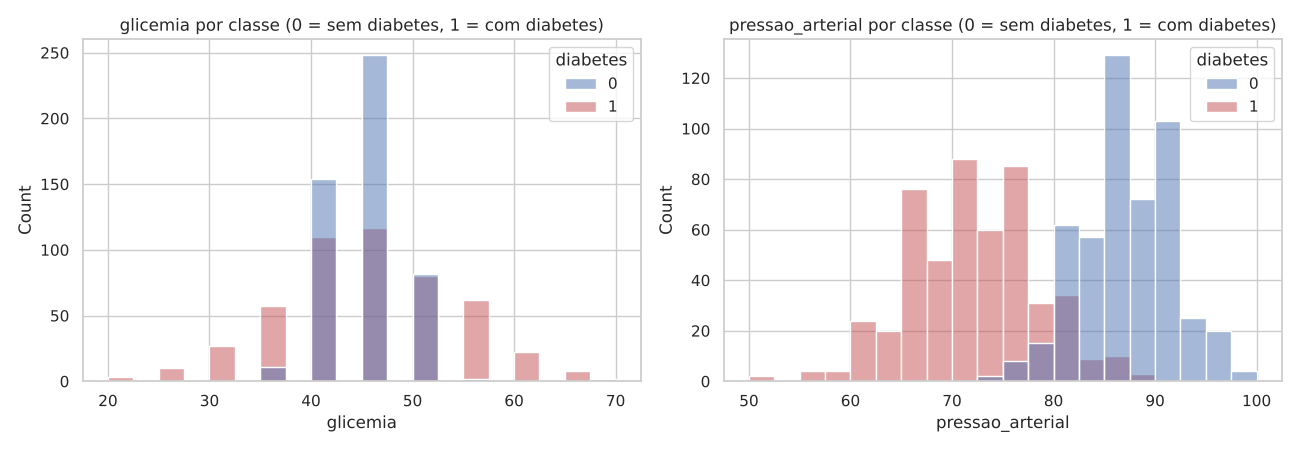

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["glicemia", "pressao_arterial"]):
    sns.histplot(data=df, x=col, hue="diabetes", bins=20, multiple="layer", palette=["#4C72B0", "#C44E52"], ax=ax)
    ax.set_title(f"{col} por classe (0 = sem diabetes, 1 = com diabetes)")
plt.tight_layout()
plt.show()

In [6]:
print("Correlações:")
df.corr().round(3)

Correlações:


,glicemia,pressao_arterial,diabetes
glicemia,1.000,-0.165,0.032
pressao_arterial,-0.165,1.000,-0.808
diabetes,0.032,-0.808,1.000


In [7]:
# Linhas duplicadas e combinações únicas
print("Linhas duplicadas:", df.duplicated().sum())

grupos = df.groupby(["glicemia", "pressao_arterial"])["diabetes"].agg(["mean", "count"])
print("Combinações únicas de (glicemia, pressão):", len(grupos))
print("Combinações que aparecem com as duas classes:", ((grupos["mean"] > 0) & (grupos["mean"] < 1)).sum())

Linhas duplicadas: 820
Combinações únicas de (glicemia, pressão): 150
Combinações que aparecem com as duas classes: 25


**O que a exploração mostra e as decisões de pré-processamento:**

- **Sem valores nulos** e com as classes **equilibradas** (497 sem diabetes e 498 com diabetes). Não é preciso preencher nem balancear nada.
- **Linhas duplicadas: mantidas.** O dataset tem 820 linhas repetidas, mas isso é esperado: as medidas são números inteiros em faixas pequenas, então só existem 150 combinações diferentes de glicemia e pressão, e muitos pacientes têm exatamente os mesmos valores. Remover as repetições distorceria as contagens que o Naive Bayes usa para aprender.
- **Escalonamento: não necessário.** O Naive Bayes Gaussiano modela cada variável separadamente, então a escala das colunas não muda o resultado.
- A **pressão arterial** tem forte relação com a classe (correlação de -0,81): a pressão média é de 86,7 nos pacientes sem diabetes e de 71,6 nos com diabetes.
- A **média da glicemia é quase igual** nas duas classes (44,1 e 44,5), mas a **dispersão é bem diferente**: quem tem diabetes aparece em toda a faixa de 20 a 70, enquanto quem não tem fica só entre 35 e 55. Ou seja, glicemias muito baixas ou muito altas só ocorrem na classe 1.
- 25 das 150 combinações aparecem nas duas classes: existe uma região de sobreposição, então nenhum modelo vai chegar a 100% de acerto.
- Observação: os valores do dataset parecem fictícios (por exemplo, uma pressão mais baixa associada a diabetes costuma ser o contrário na prática). O foco aqui é aprender o algoritmo, não tirar conclusões médicas.

## 3. Implementar o algoritmo Naive Bayes

O Naive Bayes calcula, para cada paciente, a **probabilidade de cada classe** usando o Teorema de Bayes:

`P(classe | medidas) ∝ P(classe) × P(glicemia | classe) × P(pressão | classe)`

- É chamado de **"ingênuo"** porque assume que as medidas são independentes entre si dentro de cada classe (uma simplificação, que na prática costuma funcionar bem).
- Como as medidas são números, usamos a versão **Gaussiana** (`GaussianNB`): para cada classe, o modelo aprende a **média** e a **variância** de cada variável e assume que elas seguem uma curva normal (em sino).

## 4. Treinar o modelo

In [8]:
X = df[["glicemia", "pressao_arterial"]]
y = df["diabetes"]

# 80% treino / 20% teste; stratify mantém a proporção das classes nos dois conjuntos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Treino:", len(X_train), "pacientes | Teste:", len(X_test), "pacientes")

modelo = GaussianNB()
modelo.fit(X_train, y_train)
print("Modelo treinado!")

Treino: 796 pacientes | Teste: 199 pacientes
Modelo treinado!


In [9]:
# O que o modelo aprendeu: média e variância de cada variável em cada classe
aprendido = pd.DataFrame({
    "média sem diabetes": modelo.theta_[0],
    "média com diabetes": modelo.theta_[1],
    "variância sem diabetes": modelo.var_[0],
    "variância com diabetes": modelo.var_[1],
}, index=["glicemia", "pressao_arterial"]).round(2)

print("Probabilidade a priori das classes:", modelo.class_prior_)
aprendido

Probabilidade a priori das classes: [0.5 0.5]


,média sem diabetes,média com diabetes,variância sem diabetes,variância com diabetes
glicemia,44.11,44.42,13.97,71.78
pressao_arterial,86.72,71.60,20.32,38.62


Repare na **variância da glicemia**: é bem maior na classe com diabetes (cerca de 72) do que na classe sem diabetes (cerca de 14). É assim que o modelo consegue usar a glicemia, mesmo com a média quase igual: uma glicemia muito afastada da média "combina mais" com a classe de maior variância.

## 5. Avaliar o desempenho

In [10]:
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

metricas = pd.Series({
    "Acurácia": accuracy_score(y_test, y_pred),
    "Precisão": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC AUC": roc_auc_score(y_test, y_prob),
}).round(3)
metricas

Acurácia    0.910
Precisão    0.910
Recall      0.910
F1-score    0.910
ROC AUC     0.976
dtype: float64

In [11]:
print(classification_report(y_test, y_pred, target_names=["sem diabetes", "com diabetes"]))

              precision    recall  f1-score   support

sem diabetes       0.91      0.91      0.91        99
com diabetes       0.91      0.91      0.91       100

    accuracy                           0.91       199
   macro avg       0.91      0.91      0.91       199
weighted avg       0.91      0.91      0.91       199



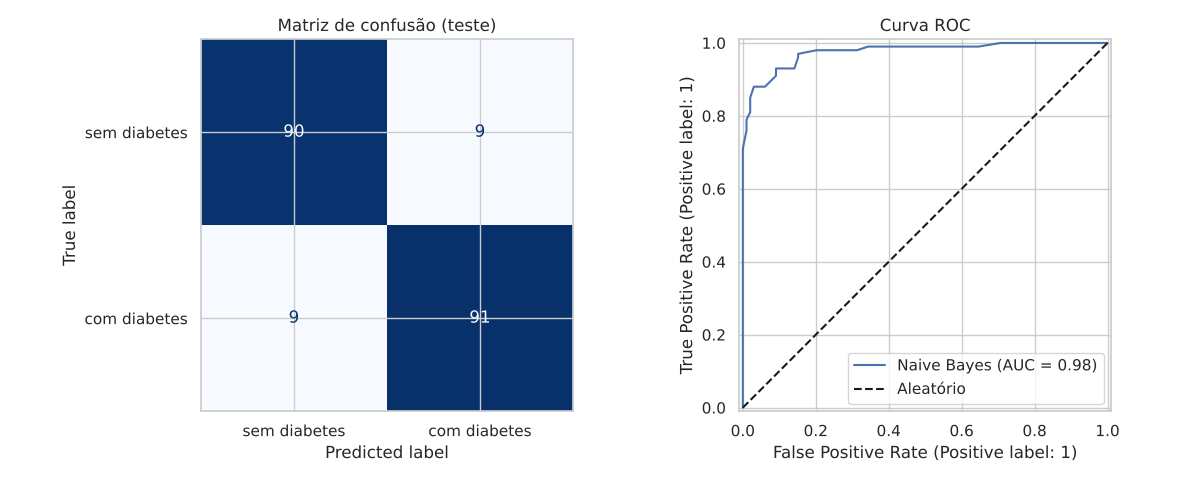

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["sem diabetes", "com diabetes"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Matriz de confusão (teste)")

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="Naive Bayes")
axes[1].plot([0, 1], [0, 1], "k--", label="Aleatório")
axes[1].set_title("Curva ROC")
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
# Validação cruzada: confere se o resultado não depende de uma divisão específica
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
acc_cv = cross_val_score(GaussianNB(), X, y, cv=kfold, scoring="accuracy")
auc_cv = cross_val_score(GaussianNB(), X, y, cv=kfold, scoring="roc_auc")
acc_base = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=kfold, scoring="accuracy")

print(f"Acurácia em cada parte: {acc_cv.round(3)}")
print(f"Acurácia média (5 partes): {acc_cv.mean():.3f}   |   ROC AUC médio: {auc_cv.mean():.3f}")
print(f"Referência (sempre chutar a classe mais comum): {acc_base.mean():.3f}")

Acurácia em cada parte: [0.95  0.92  0.93  0.92  0.935]
Acurácia média (5 partes): 0.931   |   ROC AUC médio: 0.982
Referência (sempre chutar a classe mais comum): 0.497


**Leitura da avaliação:**
- No teste, o modelo acertou cerca de **91%** dos pacientes (acurácia de 0,91), com precisão, recall e F1 também em 0,91 e **ROC AUC de 0,976** (1,0 seria perfeito).
- A matriz de confusão mostra **90 e 91 acertos** nas duas classes e **9 erros de cada tipo**: 9 pacientes sem diabetes classificados como com diabetes (falsos positivos) e 9 com diabetes classificados como sem (falsos negativos). O modelo erra por igual nos dois lados.
- A validação cruzada confirma o resultado (acurácia média de 0,93), bem acima da referência de chutar a classe mais comum (0,50), então o modelo realmente aprendeu um padrão.
- Em um problema de saúde, o erro mais grave é o **falso negativo** (deixar de identificar quem tem a doença). Aqui o recall de 0,91 significa que 9 em cada 100 pacientes com diabetes passariam despercebidos.

## 6. Apresentar os resultados

In [14]:
# Quanto cada variável contribui? Comparando o modelo com cada uma sozinha
resultados = {}
for nome, colunas in [("Glicemia + pressão", ["glicemia", "pressao_arterial"]),
                      ("Só pressão arterial", ["pressao_arterial"]),
                      ("Só glicemia", ["glicemia"])]:
    resultados[nome] = {
        "acurácia (CV)": cross_val_score(GaussianNB(), df[colunas], y, cv=kfold, scoring="accuracy").mean(),
        "ROC AUC (CV)": cross_val_score(GaussianNB(), df[colunas], y, cv=kfold, scoring="roc_auc").mean(),
    }
pd.DataFrame(resultados).T.round(3)

,acurácia (CV),ROC AUC (CV)
Glicemia + pressão,0.931,0.982
Só pressão arterial,0.919,0.973
Só glicemia,0.676,0.727


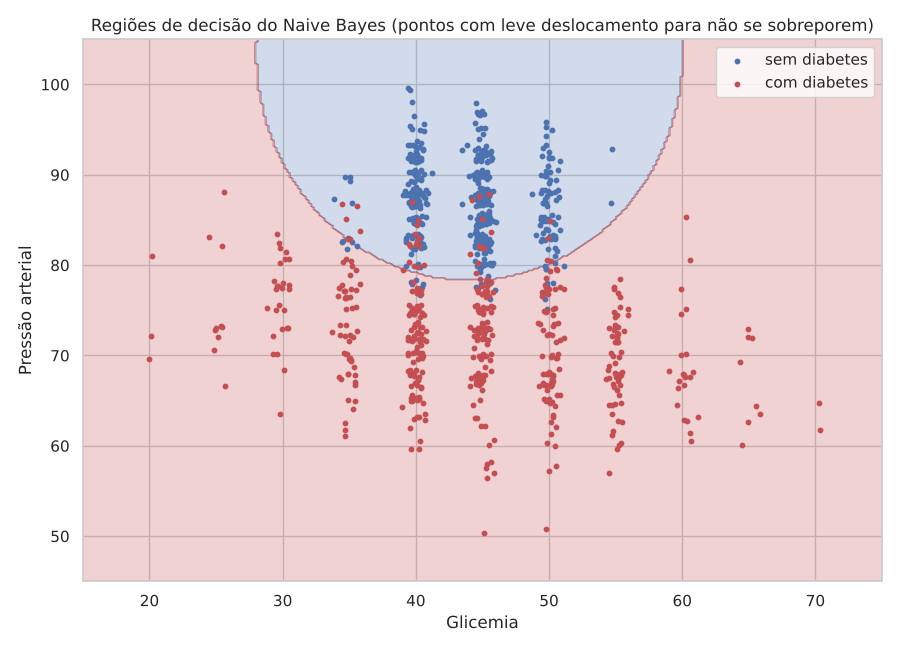

In [15]:
# Regiões de decisão: como o modelo separa as classes no plano glicemia x pressão
g_vals = np.linspace(15, 75, 300)
p_vals = np.linspace(45, 105, 300)
gg, pp = np.meshgrid(g_vals, p_vals)
grade = pd.DataFrame({"glicemia": gg.ravel(), "pressao_arterial": pp.ravel()})
regiao = modelo.predict(grade).reshape(gg.shape)

rng = np.random.default_rng(0)
plt.figure(figsize=(9, 6.5))
plt.contourf(gg, pp, regiao, alpha=0.25, cmap=ListedColormap(["#4C72B0", "#C44E52"]))
for classe, cor, nome in [(0, "#4C72B0", "sem diabetes"), (1, "#C44E52", "com diabetes")]:
    sub = df[df["diabetes"] == classe]
    plt.scatter(sub["glicemia"] + rng.normal(0, 0.4, len(sub)),
                sub["pressao_arterial"] + rng.normal(0, 0.4, len(sub)),
                s=10, color=cor, label=nome)
plt.title("Regiões de decisão do Naive Bayes (pontos com leve deslocamento para não se sobreporem)")
plt.xlabel("Glicemia")
plt.ylabel("Pressão arterial")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Usando o modelo para classificar novos pacientes
novos = pd.DataFrame({"glicemia": [45, 45, 25], "pressao_arterial": [90, 65, 80]})
probabilidades = modelo.predict_proba(novos)[:, 1]

resultado_novos = novos.copy()
resultado_novos["previsão"] = np.where(modelo.predict(novos) == 1, "com diabetes", "sem diabetes")
resultado_novos["prob. de diabetes"] = probabilidades.round(3)
resultado_novos

,glicemia,pressao_arterial,previsão,prob. de diabetes
0,45,90,sem diabetes,0.005
1,45,65,com diabetes,1.000
2,25,80,com diabetes,1.000


## Conclusões

- **Modelo:** Naive Bayes Gaussiano com glicemia e pressão arterial, treinado com 796 pacientes e testado em 199.
- **Desempenho:** 91% de acurácia no teste (93% na validação cruzada), F1 de 0,91 e ROC AUC de 0,976, contra 50% de um chute pela classe mais comum.
- **O que mais pesa:** a **pressão arterial** carrega a maior parte da informação (sozinha já dá cerca de 92% de acurácia na validação cruzada). A **glicemia** sozinha acerta bem menos (cerca de 68%), mas ajuda a refinar a previsão: pacientes com glicemia muito baixa ou muito alta só aparecem na classe com diabetes.
- **Limites:** os dados são aparentemente fictícios e as classes se sobrepõem em parte (25 combinações aparecem nas duas classes), então há um teto de acerto abaixo de 100%. O modelo erra 9 pacientes com diabetes em 100, o que, em um uso real, exigiria cuidado.
- **Próximos passos possíveis:** testar outros algoritmos (regressão logística, árvore de decisão) para comparar com o Naive Bayes e, em dados reais, incluir mais variáveis (idade, IMC, histórico familiar).